# Area in Drought over IPCC's European regions 

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a timeseries of the area in drought over Europe and subregions over Europe. 
For a study from Joey & Francesca

## Setup and Settings

#### Load libraries

In [1]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [2]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.nan
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [3]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 2005
yyyy_end  = 2026
indicator = "SPEI"
window    = 12
yyyy      = 2025
mm        = "09"
dataset   = "era5t"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
#ipath_era5t= f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
cwd       = "/home/nejk/code/drought-on-demand"

In [4]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]#[window:]
print(dates)
print(dates.size)

DatetimeIndex(['2005-01-31', '2005-02-28', '2005-03-31', '2005-04-30',
               '2005-05-31', '2005-06-30', '2005-07-31', '2005-08-31',
               '2005-09-30', '2005-10-31',
               ...
               '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30',
               '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31',
               '2025-11-30', '2025-12-31'],
              dtype='datetime64[ns]', length=252, freq='ME')
252


### Landmask and area

In [5]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

/usr/local/apps/python3/3.12.9-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.39.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Regions of interest

       Continent  Type               Name Acronym  \
0          POLAR  Land  Greenland/Iceland     GIC   
1  NORTH-AMERICA  Land  N.W.North-America     NWN   
2  NORTH-AMERICA  Land  N.E.North-America     NEN   
3  NORTH-AMERICA  Land    W.North-America     WNA   
4  NORTH-AMERICA  Land    C.North-America     CNA   

                                            geometry  
0  POLYGON ((-10 62, -10.4375 62, -10.875 62, -11...  
1  POLYGON ((-105 50, -105.4386 50, -105.87719 50...  
2  POLYGON ((-50 50, -50.44 50, -50.88 50, -51.32...  
3  POLYGON ((-130 50, -129.5614 50, -129.12281 50...  
4  POLYGON ((-90 50, -90 49.5614, -90 49.12281, -...  


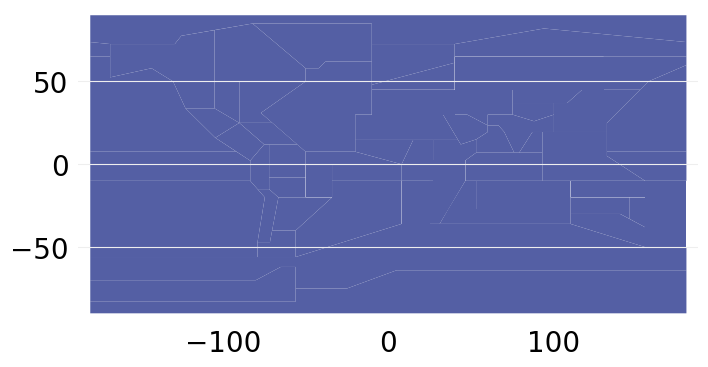

In [41]:
# use external shapefile to incl contended territories?
shpfile = gpd.read_file("./regions/IPCC-WGI-reference-regions-v4.shp")
print(shpfile.head())
shpfile.plot()
shpfile=shpfile.to_crs('epsg:4326')

In [42]:
extent = (shpfile[shpfile["Name"] == "Mediterranean"]).bounds
lon1   = extent.minx.values[0]
lon2   = extent.maxx.values[0]
lat1   = extent.miny.values[0]
lat2   = extent.maxy.values[0]

45.0


### Masks 

        Continent        Type           Name Acronym  \
19  EUROPE-AFRICA  Land-Ocean  Mediterranean     MED   

                                             geometry  
19  POLYGON ((-10 30, -10 30.42857, -10 30.85714, ...  


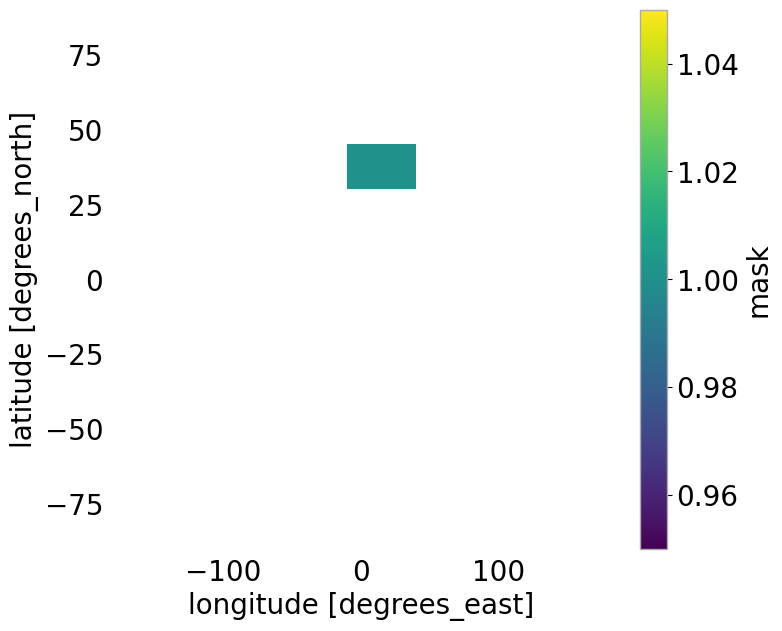

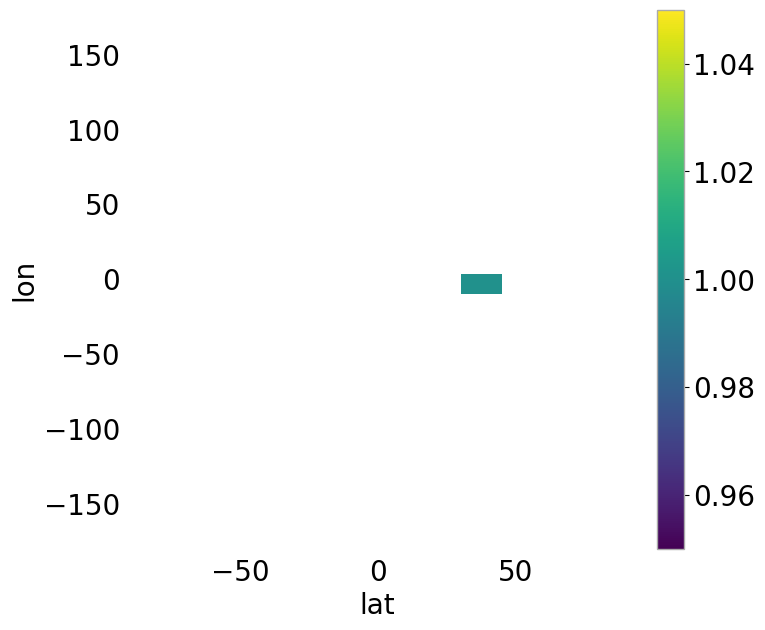

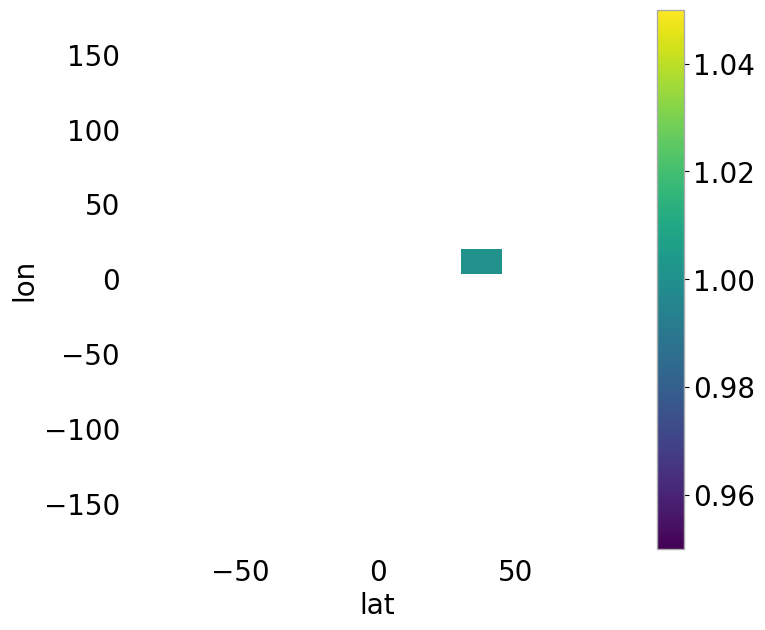

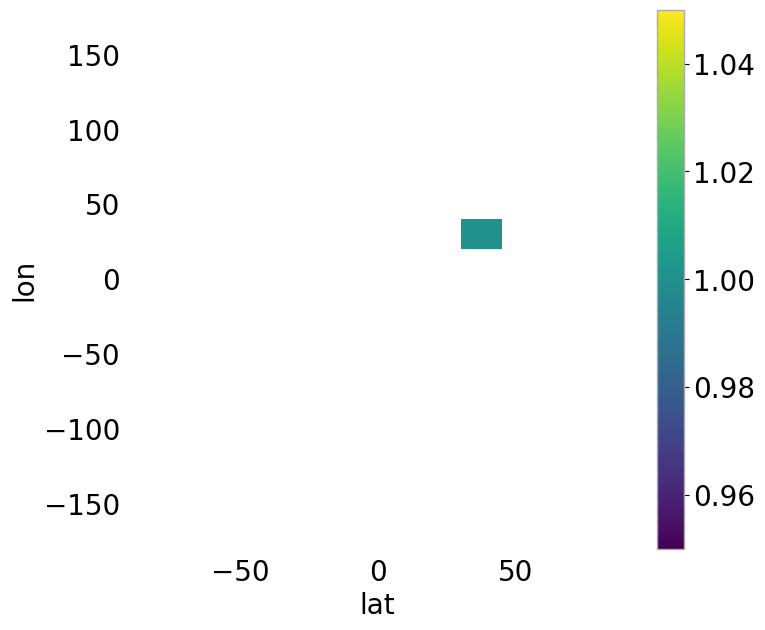

In [44]:
# from Joey: the "Name" you want is "Mediterranean" and then we have subregions within that WMED (3.5 > lon), CMED (3.5 < lon < 20) and EMED (20 > lon)
print(shpfile[shpfile["Name"] == "Mediterranean"])
medmask = regionmask.mask_geopandas((shpfile[shpfile["Name"] == "Mediterranean"]), lmask.lon, lmask.lat)
medmask = xr.where(medmask >= 1, 1, np.nan)
medmask_cut = medmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
plt.figure()
medmask.plot()
# and manual subreguions
# WMED
wmedmask = medmask
wmedmask = xr.where(wmedmask.lon < 3.5, wmedmask, np.nan)
wmedmask_cut = wmedmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
plt.figure(); wmedmask.plot()
# CMED
cmedmask = medmask
cmedmask = xr.where(cmedmask.lon > 3.5, cmedmask, np.nan)
cmedmask = xr.where(cmedmask.lon < 20, cmedmask, np.nan)
cmedmask_cut = cmedmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
plt.figure(); cmedmask.plot()
# EMED
emedmask = medmask
emedmask = xr.where(emedmask.lon > 20, emedmask, np.nan)
emedmask_cut = emedmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
plt.figure(); emedmask.plot()


## ERA5-Drought

### Read drought index 

In [48]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq[:-3]:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
#print(filelist[:-8])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
print(drought_index[window])

<xarray.Dataset> Size: 23MB
Dimensions:  (time: 237, lat: 61, lon: 201)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2006-01-01T06:00:00 ... 2025-09-01T06:...
  * lat      (lat) float64 488B 45.0 44.75 44.5 44.25 ... 30.75 30.5 30.25 30.0
  * lon      (lon) float64 2kB -10.0 -9.75 -9.5 -9.25 ... 39.25 39.5 39.75 40.0
Data variables:
    SPEI12   (time, lat, lon) float64 23MB dask.array<chunksize=(1, 61, 201), meta=np.ndarray>
Attributes: (12/17)
    title:                   SPEI12
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 27/10/2024 12:22:08 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    extent:                  -180,-90,180,90
    resolution:              0.25x0.25
    climate_start_date:      1991-01-01
    climate_end_date:        2020-12-31

## Mask for Mediterranean

### Mask data

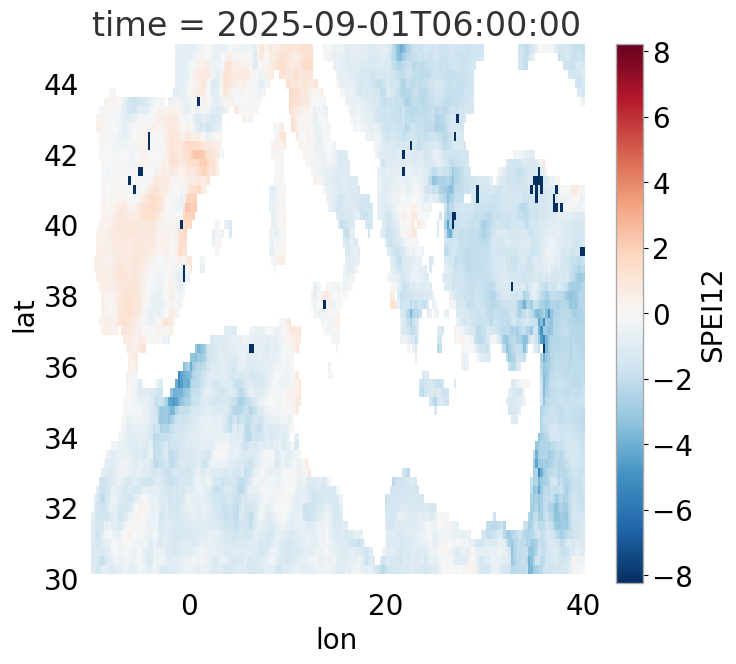

In [49]:
masked_drought_index = drought_index[window] * medmask_cut
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan

### Calculate area in drought

In [51]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (medmask_cut*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries

In [32]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']

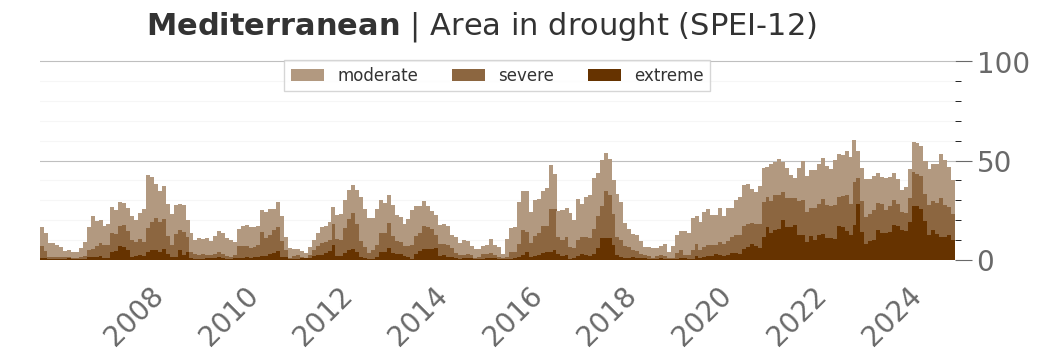

In [40]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
#title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
title1 = r"$\bf{" + f"Mediterranean" + "}$"
fig.suptitle(f"{title1} | Area in drought ({indicator}-{window})", fontsize=22)
#fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
ax1.set_ylabel("Area in drought [%]", size=18)
ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='dimgray')
ax1.xaxis.label.set_color('None')
ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
# Major ticks every 20, minor ticks every 5
#https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
# And a corresponding grid
#ax1.grid(which='minor')
# Or if you want different settings for the grids:
#ax1.grid(which='minor', alpha=0.2)
#ax1.grid(which='major', alpha=0.5)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    
plt.savefig(f"figures/Mediterranean_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

## Mask for Subregions

### Loop over all subregions: mask, calculate and plot 

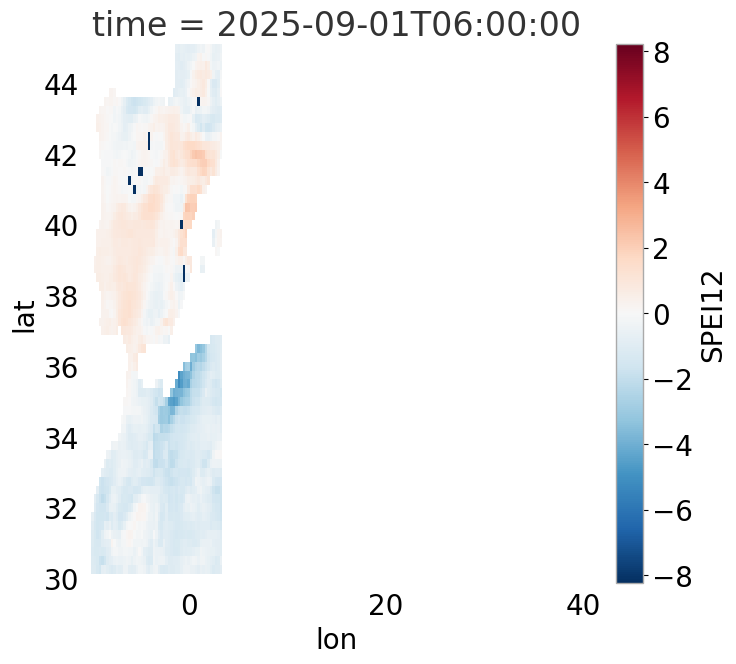

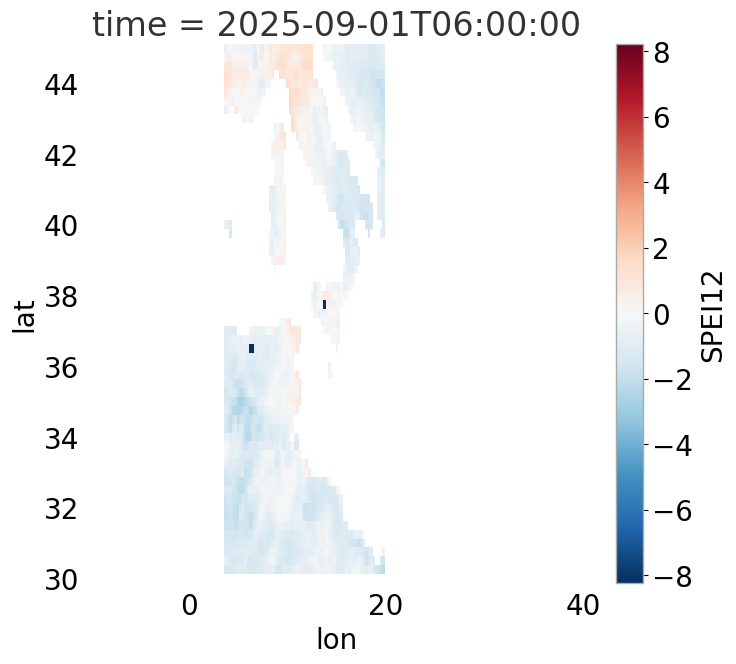

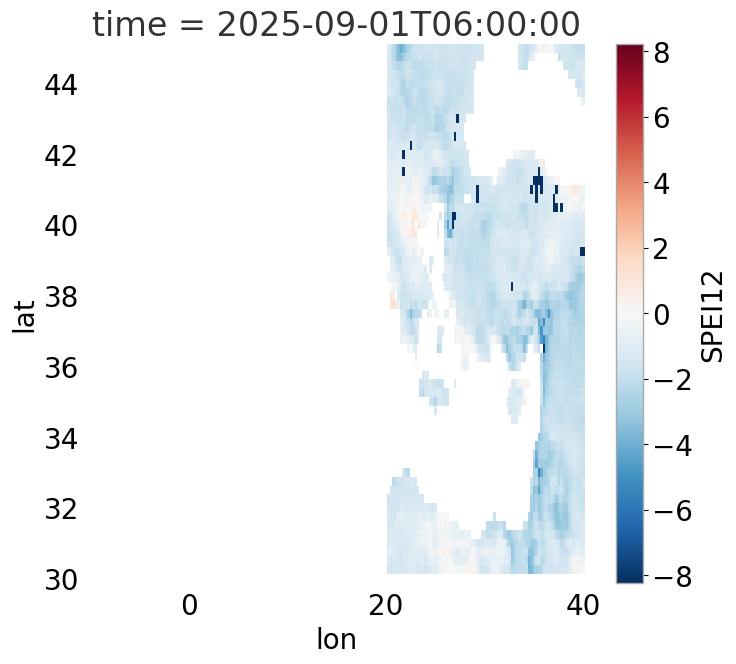

In [54]:
aid = {}

for subregion in ["WMED", "CMED", "EMED"]:

    if subregion == "WMED":
        subregionmask = wmedmask_cut
    if subregion == "CMED":
        subregionmask = cmedmask_cut
    if subregion == "EMED":
        subregionmask = emedmask_cut

    aid[subregion] = {}
    
    # MASK
    masked_drought_index = drought_index[window] * subregionmask
    masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)

    # debugging
    plt.figure()
    masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()
    
    area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))[0,:,:]
    area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
    area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
    area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan

    # Calculate area in drought
    area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
    
    swindow=f"w{window}"
    aid[subregion][swindow] = {}
    
    for severity in ['moderate','severe','extreme','any']:
            
        if severity == "mild":
            thresh_min = -1
            thresh_max = 0
        if severity == "moderate":
            thresh_min = -1.5
            thresh_max = -1
        if severity == "severe":
            thresh_min = -2
            thresh_max = -1.5
        if severity == "extreme":
            thresh_min = -999
            thresh_max = -2
        if severity == "any":
            thresh_min = -999
            thresh_max = -1
    
        rdi = masked_drought_index[f'{indicator}{window}']
        dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
        tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (subregionmask*area_3d_adj).sum(dim=["lat", "lon"])
        aid[subregion][swindow][severity] = tmp.to_pandas() 
    
        del(tmp, dmask)


### Plot timeseries

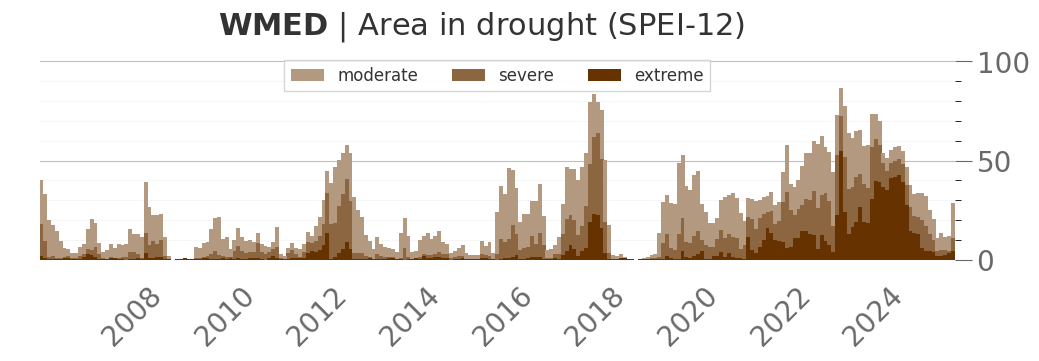

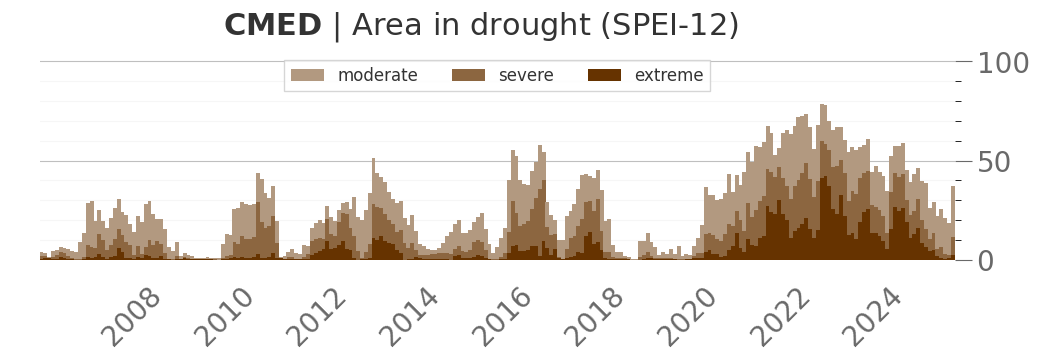

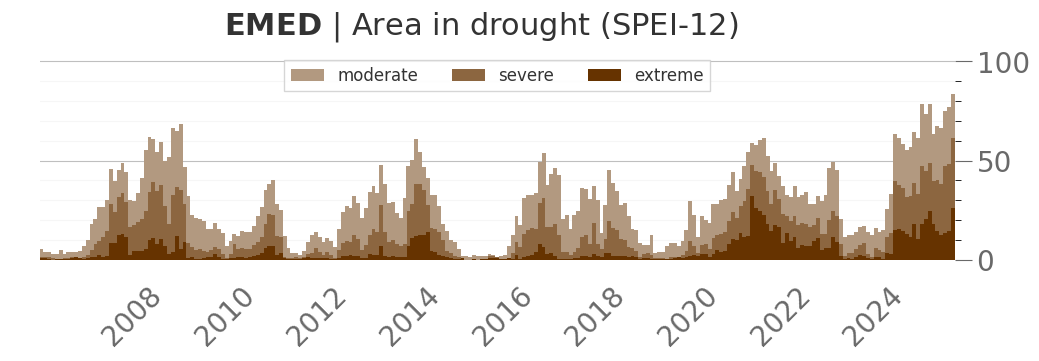

In [53]:
for subregion in ["WMED", "CMED", "EMED"]:

    # plot
    fig, ax1 = plt.subplots(1,1, figsize=(12,4))
    #title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
    title1 = r"$\bf{" + f"{subregion}" + "}$"
    fig.suptitle(f"{title1} | Area in drought ({indicator}-{window})", fontsize=22)
    #fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 20}
    plt.rc('font', **font)
    
    severities = ['extreme','severe','moderate']
    pidata2 = aid[subregion][f'w{window}']['extreme']#[f'{indicator}{window}']
    pidata3 = aid[subregion][f'w{window}']['severe']#[f'{indicator}{window}']
    pidata4 = aid[subregion][f'w{window}']['moderate']#[f'{indicator}{window}']
    apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
    #apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
    bottom = np.zeros(len(apidata.index))
    for i in range(len(apidata.columns)):
        p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                    alpha=1, 
                    width=relativedelta.relativedelta(months=1), 
                    label=severities[i], 
                    bottom=bottom,
                    align='edge')
        bottom += apidata.iloc[:,i]
    ax1.set_ylabel("Area in drought [%]", size=18)
    ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
    ax1.margins(x=0)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['left'].set_visible(False)
    ax1.tick_params(axis='y', colors='dimgray')
    ax1.tick_params(axis='x', colors='dimgray')
    ax1.xaxis.label.set_color('None')
    ax1.yaxis.label.set_color('None')
    ax1.minorticks_on()
    ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
    # Major ticks every 20, minor ticks every 5
    #https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
    major_ticks = np.arange(0, 150, 50)
    minor_ticks = np.arange(0, 150, 10)
    ax1.set_yticks(major_ticks)
    ax1.set_yticks(minor_ticks, minor=True)
    ax1.yaxis.tick_right()
    # And a corresponding grid
    #ax1.grid(which='minor')
    # Or if you want different settings for the grids:
    #ax1.grid(which='minor', alpha=0.2)
    #ax1.grid(which='major', alpha=0.5)
    ax1.tick_params(which='minor', length=4)
    ax1.tick_params(which='major', length=12)
    #ax1.grid(True)
    ax1.set_axisbelow(True)
    ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
    ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
    ax1.set_ylim([0,105])
    for tick in ax1.get_xticklabels():
        tick.set_rotation(45)
        
    plt.savefig(f"figures/{subregion}_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
                bbox_inches=None, pad_inches=0.1,
                facecolor='auto', edgecolor='auto',
                backend=None)
    plt.show()